# PathSnap — Dataset exploration (EDA)
Partitions used: **train (80 trips)** and **student_test (10 trips)**. Evaluator trips are not present/used.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx, os
from src.io import load_trip, trip_ids, DATA_DIR, PARTITIONS
plt.rcParams['figure.dpi'] = 100

## 1. Inventory: trips, files, observation counts, network size

In [2]:
rows = []
for part in ['train', 'test']:
    for t in trip_ids(part):
        d = DATA_DIR / PARTITIONS[part] / t
        tr = load_trip(t, part)
        trk = tr['track']; dt = np.diff(trk.t.values)
        rows.append(dict(partition=part, trip=t, files=len(os.listdir(d)),
            n_gps=len(trk), n_nodes=len(tr['nodes']), n_arcs=len(tr['arcs']),
            route_len=0 if tr['route'] is None else len(tr['route']),
            missing=int(trk.isna().sum().sum()), dup_t=int(trk.t.duplicated().sum()),
            non_monotonic=int((dt <= 0).sum()), pct_dt1=float((dt == 1).mean()*100),
            max_gap_s=float(dt.max()), n_gaps_gt5s=int((dt > 5).sum()),
            duration_min=(trk.t.max()-trk.t.min())/60,
            lon_min=trk.lon.min(), lon_max=trk.lon.max(), lat_min=trk.lat.min(), lat_max=trk.lat.max(),
            route_in_arcs=bool(tr['route'] is None or (tr['route'] < len(tr['arcs'])).all())))
inv = pd.DataFrame(rows)
inv.to_csv('../results/eda_inventory.csv', index=False)
inv.groupby('partition')[['n_gps','n_nodes','n_arcs','route_len','missing','dup_t','non_monotonic','max_gap_s','n_gaps_gt5s','duration_min']].describe().T.round(1)

partition             test   train
n_gps        count    10.0    80.0
             mean   1916.0  2605.2
             std    1335.4  3312.3
             min     262.0   361.0
             25%     917.8   945.8
...                    ...     ...
duration_min min       4.4     7.5
             25%      17.3    20.4
             50%      30.2    28.5
             75%      47.9    62.8
             max      66.7  2567.2

[80 rows x 2 columns]

In [3]:
print(inv.groupby('partition').trip.count())
print('All route arc ids valid:', inv.route_in_arcs.all())
print('Trips with a gap > 5 s:', (inv.n_gaps_gt5s > 0).sum())
inv.sort_values('max_gap_s', ascending=False).head(8)[['partition','trip','n_gps','max_gap_s','n_gaps_gt5s','pct_dt1']]

partition
test     10
train    80
Name: trip, dtype: int64
All route arc ids valid: True
Trips with a gap > 5 s: 47


,partition,trip,n_gps,max_gap_s,n_gaps_gt5s,pct_dt1
72,train,00000090,536,153064.0,20,58.130841
61,train,00000078,2909,52810.0,124,75.515818
55,train,00000069,2067,2658.0,2,98.935140
16,train,00000021,15783,2161.0,2,99.961982
8,train,00000011,2828,909.0,1,99.964627
34,train,00000042,7739,670.0,45,98.953218
64,train,00000081,3224,536.0,129,71.982625
18,train,00000024,801,458.0,4,97.125000


## 2. Sampling intervals and trajectory length

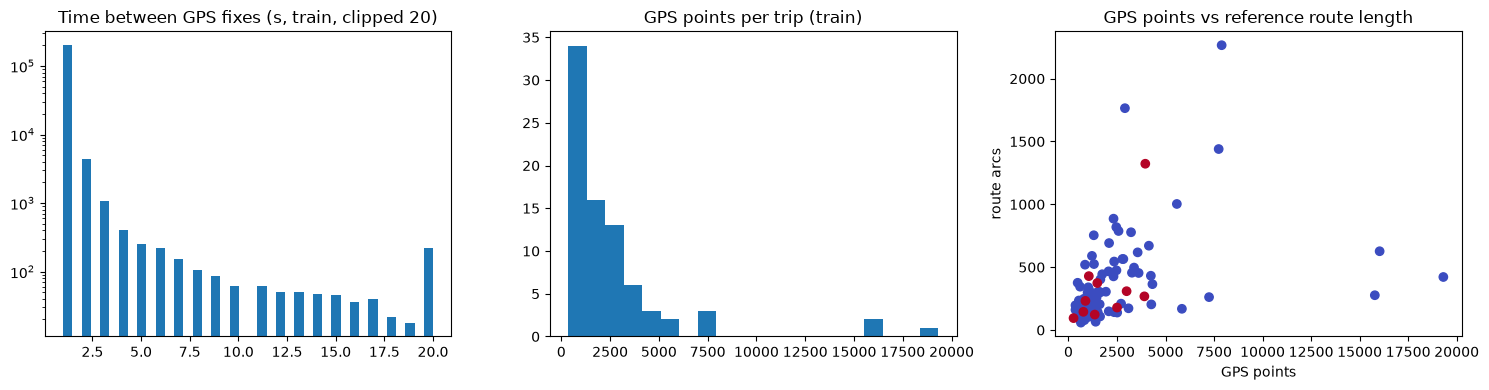

96.50% of steps are exactly 1 s


In [4]:
dts = np.concatenate([np.diff(load_trip(t, 'train')['track'].t.values) for t in trip_ids('train')])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.clip(dts, 0, 20), bins=40); ax[0].set_yscale('log'); ax[0].set_title('Time between GPS fixes (s, train, clipped 20)')
ax[1].hist(inv[inv.partition=='train'].n_gps, bins=20); ax[1].set_title('GPS points per trip (train)')
ax[2].scatter(inv.n_gps, inv.route_len, c=(inv.partition=='test'), cmap='coolwarm'); ax[2].set_xlabel('GPS points'); ax[2].set_ylabel('route arcs'); ax[2].set_title('GPS points vs reference route length')
plt.tight_layout(); plt.savefig('../results/plots/eda_sampling.png'); plt.show()
print(f'{(dts==1).mean()*100:.2f}% of steps are exactly 1 s')

## 3. Spatial extent and coordinate plausibility

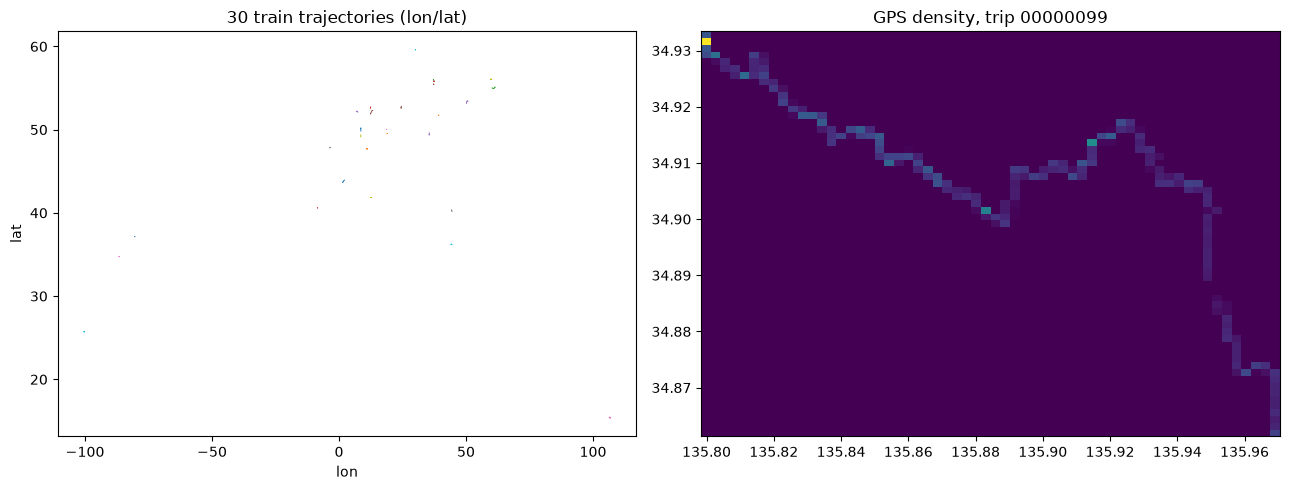

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for t in trip_ids('train')[:30]:
    trk = load_trip(t, 'train')['track']; ax[0].plot(trk.lon, trk.lat, lw=0.7)
ax[0].set_title('30 train trajectories (lon/lat)'); ax[0].set_xlabel('lon'); ax[0].set_ylabel('lat')
trk = load_trip('00000099','train')['track']
ax[1].hist2d(trk.lon, trk.lat, bins=60); ax[1].set_title('GPS density, trip 00000099')
plt.tight_layout(); plt.savefig('../results/plots/eda_extent.png'); plt.show()

## 4. Road-network connectivity (train sample)

In [6]:
conn = []
for t in trip_ids('train')[::8]:
    tr = load_trip(t, 'train')
    G = nx.DiGraph(); G.add_nodes_from(range(len(tr['nodes']))); G.add_edges_from(tr['arcs'].values)
    wcc = list(nx.weakly_connected_components(G)); scc = list(nx.strongly_connected_components(G))
    deg = np.array([d for _, d in G.degree()])
    conn.append(dict(trip=t, nodes=G.number_of_nodes(), arcs=G.number_of_edges(), weak_components=len(wcc),
        largest_wcc_pct=100*max(map(len, wcc))/G.number_of_nodes(), strong_components=len(scc),
        isolated_nodes=int((deg==0).sum()), mean_degree=deg.mean(),
        two_way_pct=100*np.mean([G.has_edge(v,u) for u,v in G.edges()])))
conn = pd.DataFrame(conn); conn.to_csv('../results/eda_network.csv', index=False); conn.round(2)

,trip,nodes,arcs,weak_components,largest_wcc_pct,strong_components,isolated_nodes,mean_degree,two_way_pct
0,00000001,88809,165498,175,97.80,1942,0,3.73,81.85
1,00000011,2649,5393,2,99.70,2,0,4.07,99.76
2,00000021,732,1510,3,95.08,3,0,4.13,98.81
3,00000031,59059,125827,67,98.34,156,0,4.26,96.00
4,00000039,1185,2388,3,98.23,3,0,4.03,99.83
5,00000048,1308,2592,5,98.17,5,0,3.96,96.76
6,00000060,15128,30075,28,98.10,192,0,3.98,94.54
7,00000070,1799,3776,3,99.61,3,0,4.20,100.00
8,00000081,2791,5042,8,90.51,8,0,3.61,87.62
9,00000090,4010,7942,20,94.09,90,0,3.96,94.13


## 5. Folium map: raw GPS vs reference route vs road network

In [7]:
from src.viz import trip_map
m = trip_map(load_trip('00000099','train'), title='Trip 00000099 (train)')
m.save('../maps/eda_trip_00000099.html'); m

/HDD/lab/College/Year-3/Sem-5/ML/Hackathon/ml-hackathon-pathsnap-5/.venv/lib/python3.12/site-packages/folium/raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 6. Data-quality notes / assumptions
- Coordinates are (lon, lat) WGS84 near Kyoto; projected to UTM 53N (metres) for all distances.
- ~97% of steps are 1 s; larger gaps are kept and exposed to models/HMM via `dt`.
- Each trip ships its own road network; arcs are directed (two-way roads = two arcs).
- `.route` gives arcs in order but no timestamps, so per-point labels are derived by projecting GPS onto route arcs with a monotonic pointer — labels are approximate near junctions.
- GPS points with no arc within 50 m become 'no candidate' points (candidate miss).